# EDA — PaySim como proxy de Pix

Esta EDA não descreve o dataset. Ela **audita** o dataset.

O PaySim é o benchmark mais usado em portfólio de antifraude, e a maioria
dos notebooks reporta AUC acima de 0,99. Antes de treinar qualquer coisa,
as perguntas são:

1. Esse resultado é detecção ou é a assinatura do gerador?
2. O eixo temporal permite validação honesta?
3. Que sinal sobra depois de tirar os atalhos?

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config, data, features, leakage

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
})
AZUL, VERMELHO, VERDE, CINZA = "#1f4e79", "#c0392b", "#27ae60", "#7f8c8d"

df = data.load()
print(f"{len(df):,} transacoes | fraude {df[config.TARGET].mean():.4%}".replace(",", "."))
display(data.resumo(df))

6.362.620 transacoes | fraude 0.1291%


,transacoes,fraudes,valor_total,valor_fraudado,taxa_fraude
tipo,,,,,
CASH_OUT,2237500,4116,3.944130e+11,5.989202e+09,0.001840
TRANSFER,532909,4097,4.852920e+11,6.067213e+09,0.007688
CASH_IN,1399284,0,2.363674e+11,0.000000e+00,0.000000
DEBIT,41432,0,2.271992e+08,0.000000e+00,0.000000
PAYMENT,2151495,0,2.809337e+10,0.000000e+00,0.000000


Fraude existe apenas em **TRANSFER** e **CASH_OUT**. Nos outros três tipos
a contagem é exatamente zero — não é raridade, é impossibilidade por
construção do simulador.

Manter esses tipos no treino deixaria o modelo aprender um filtro que uma
cláusula `WHERE` já resolve, e diluiria a prevalência de 0,296% para
0,129%, inflando toda métrica. O escopo daqui em diante são os dois tipos
onde fraude pode acontecer.

## 1. A assinatura do gerador

O PaySim cria fraude por um roteiro fixo: assume a conta e transfere
**exatamente o saldo inteiro**. Isso deixa uma marca aritmética que
nenhuma fraude real tem — em dado de verdade o valor transferido não bate
ao centavo com o saldo anterior.

In [2]:
escopo = features.filtrar_escopo(df)
print(f"escopo: {len(escopo):,} transacoes | fraude {escopo[config.TARGET].mean():.4%}".replace(",", "."))
print()
display(leakage.auditar(escopo).style.format({
    "em_fraude": "{:.2%}", "em_legitima": "{:.2%}", "razao": "{:,.0f}x"
}))

escopo: 2.770.409 transacoes | fraude 0.2965%



,artefato,em_fraude,em_legitima,razao
0,conta drenada ao centavo (saldo_antes == valor),97.82%,0.00%,"900,665x"
1,origem zerada apos a transacao,98.05%,90.10%,1x
2,destino zerado antes e depois,49.63%,0.06%,804x
3,contabilidade da origem fecha exatamente,99.45%,9.21%,11x


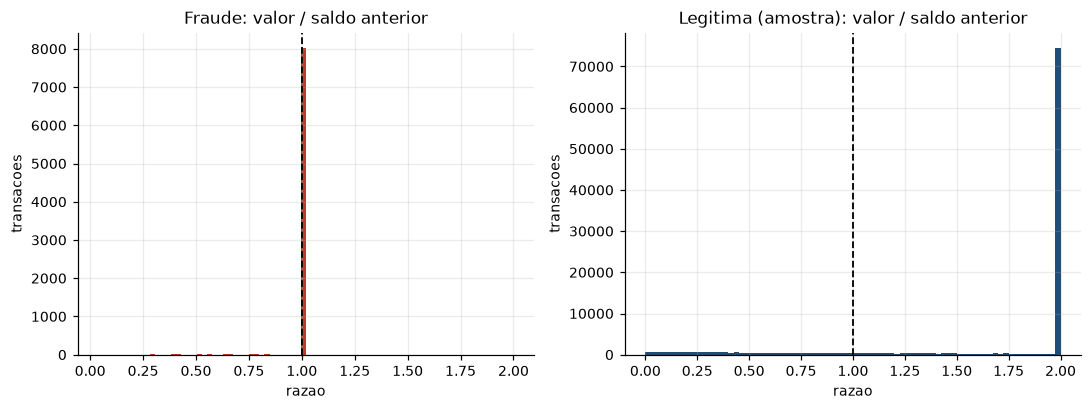

A barra vertical em 1,0 e a conta drenada por inteiro.
Em fraude ela concentra quase tudo; em transacao legitima, nada.


In [3]:
f = escopo[escopo[config.TARGET] == 1]
l = escopo[escopo[config.TARGET] == 0].sample(200_000, random_state=0)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, sub, titulo, cor in [
    (axes[0], f, "Fraude", VERMELHO), (axes[1], l, "Legitima (amostra)", AZUL)
]:
    razao = (sub["valor"] / sub["saldo_origem_antes"].replace(0, np.nan)).clip(0, 2)
    ax.hist(razao.dropna(), bins=80, color=cor)
    ax.axvline(1.0, color="black", ls="--", lw=1.2)
    ax.set_title(f"{titulo}: valor / saldo anterior")
    ax.set_xlabel("razao"); ax.set_ylabel("transacoes")
plt.tight_layout(); plt.show()

print("A barra vertical em 1,0 e a conta drenada por inteiro.")
print("Em fraude ela concentra quase tudo; em transacao legitima, nada.")

### A regra de duas linhas

Se a marca é essa, não é preciso modelo nenhum para explorá-la.

In [4]:
reg = leakage.desempenho_da_regra(escopo)
print("Regra:  saldo_origem_antes == valor  E  saldo_origem_depois == 0")
print()
print(f"  alertas gerados      : {reg['alertas']:>8,}".replace(",", "."))
print(f"  fraudes capturadas   : {reg['verdadeiros_positivos']:>8,}".replace(",", "."))
print(f"  falsos positivos     : {reg['falsos_positivos']:>8,}".replace(",", "."))
print(f"  {'-'*40}")
print(f"  recall               : {reg['recall']:>8.2%}")
print(f"  precisao             : {reg['precisao']:>8.2%}")
print(f"  do valor fraudado    : {reg['valor_capturado']/reg['valor_total_fraudado']:>8.2%}")

Regra:  saldo_origem_antes == valor  E  saldo_origem_depois == 0

  alertas gerados      :    8.025
  fraudes capturadas   :    8.024
  falsos positivos     :        1
  ----------------------------------------
  recall               :   97.70%
  precisao             :   99.99%
  do valor fraudado    :   87.48%


**97,70% de recall com 99,99% de precisão, sem treinar nada.** Um falso
positivo em 8.025 alertas.

Qualquer modelo que receba as colunas de saldo vai encontrar isso sozinho
na primeira árvore. O AUC 0,999 que circula nos notebooks é essa regra
escrita com mais passos — não é capacidade de detecção, é leitura do
gerador. Por isso os saldos ficam fora do modelo honesto.

## 2. O eixo temporal não aguenta um split

Validação honesta em dado transacional é temporal: treina no passado,
testa no futuro. Isso exige que passado e futuro sejam comparáveis.

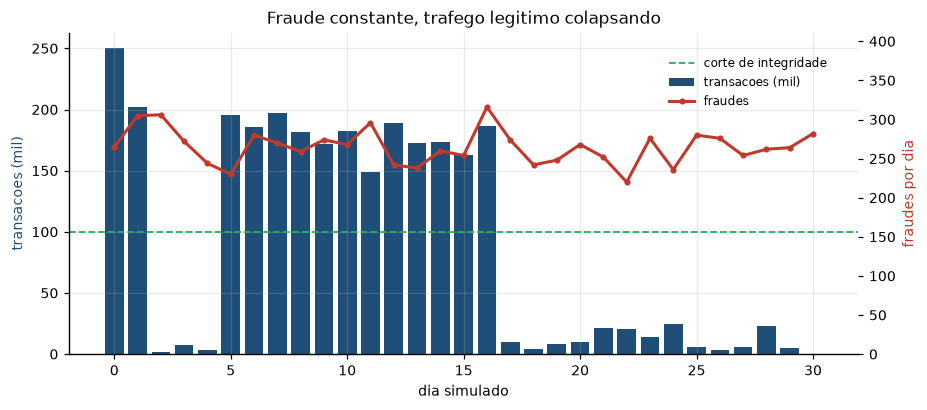

fraudes/dia : min 220, max 316, mediana 265
transacoes  : de 250.180 a 282
pior dia    : dia 30, 282 transacoes, prevalencia 100%


In [5]:
vol = features.volume_por_dia(escopo)

fig, ax1 = plt.subplots(figsize=(8.5, 3.8))
ax1.bar(vol["dia"], vol["transacoes"] / 1000, color=AZUL, label="transacoes (mil)")
ax1.set_xlabel("dia simulado"); ax1.set_ylabel("transacoes (mil)", color=AZUL)
ax1.axhline(config.VOLUME_MINIMO_DIARIO / 1000, color=VERDE, ls="--", lw=1.2,
            label="corte de integridade")

ax2 = ax1.twinx()
ax2.plot(vol["dia"], vol["fraudes"], color=VERMELHO, lw=2, marker="o", ms=3,
         label="fraudes")
ax2.set_ylabel("fraudes por dia", color=VERMELHO)
ax2.set_ylim(0, vol["fraudes"].max() * 1.3); ax2.grid(False)

ax1.set_title("Fraude constante, trafego legitimo colapsando")
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.88), frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

print(f"fraudes/dia : min {vol['fraudes'].min()}, max {vol['fraudes'].max()}, "
      f"mediana {vol['fraudes'].median():.0f}")
print(f"transacoes  : de {vol['transacoes'].max():,} a {vol['transacoes'].min():,}".replace(",", "."))
pior = vol.loc[vol["prevalencia"].idxmax()]
print(f"pior dia    : dia {int(pior['dia'])}, {int(pior['transacoes'])} transacoes, "
      f"prevalencia {pior['prevalencia']:.0%}")

O simulador emite fraude a taxa praticamente constante nos 31 dias
(~270/dia), mas para de emitir tráfego legítimo a partir do dia 17. **No
dia 30 sobram 282 transações e todas são fraude.**

Um split temporal ingênuo — treinar nos primeiros 70% do tempo, testar
nos últimos 30% — avaliaria o modelo numa população com prevalência 17
vezes maior que a de treino. O resultado não mediria generalização,
mediria a mudança de regime do simulador.

A saída adotada é recortar os dias de volume íntegro e dividir dentro
deles.

In [6]:
integros = features.dias_integros(escopo)
print(f"dias integros ({len(integros)}): {integros}")
print(f"descartados: {[int(d) for d in vol['dia'] if d not in integros]}")
print()

recorte = features.filtrar_periodo_integro(escopo)
recorte = recorte.assign(dia=recorte["hora"] // 24)
for nome, lo, hi in [("treino", 0, config.DIA_TREINO_FIM),
                     ("validacao", config.DIA_TREINO_FIM + 1, config.DIA_VALIDACAO_FIM),
                     ("teste", config.DIA_VALIDACAO_FIM + 1, 99)]:
    sub = recorte[(recorte["dia"] >= lo) & (recorte["dia"] <= hi)]
    print(f"  {nome:<10} {len(sub):>9,} transacoes | prevalencia {sub[config.TARGET].mean():.4%}".replace(",", "."))

dias integros (14): [0, 1, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]
descartados: [2, 3, 4, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]



  treino     1.566.885 transacoes | prevalencia 0.1373%
  validacao    510.803 transacoes | prevalencia 0.1519%


  teste        523.527 transacoes | prevalencia 0.1585%


## 3. Onde sobra sinal: a conta laranja

Removidos os saldos, o que resta? A resposta depende de existir histórico
por conta — e aqui o simulador impõe outra restrição.

In [7]:
for col in ["conta_origem", "conta_destino"]:
    vc = escopo[col].value_counts()
    print(f"{col:<15} {len(vc):>9,} contas unicas em {len(escopo):,} transacoes".replace(",", "."))
    print(f"{'':<15} aparecem 1x: {(vc==1).mean():>6.1%} | 2x: {(vc==2).mean():>5.1%} | "
          f"3+: {(vc>=3).mean():>5.1%} | maximo: {vc.max()}")
    print()

conta_origem    2.768.630 contas unicas em 2.770.409 transacoes
                aparecem 1x:  99.9% | 2x:  0.1% | 3+:  0.0% | maximo: 3



conta_destino     509.565 contas unicas em 2.770.409 transacoes
                aparecem 1x:  25.2% | 2x: 15.6% | 3+: 59.2% | maximo: 75



**A conta de origem aparece uma única vez em 99,9% dos casos.** O PaySim
não reutiliza pagadores, então não existe histórico do lado de quem paga:
nenhuma feature de velocidade por origem é calculável. Metade do arsenal
padrão de antifraude está indisponível.

Resta o destino. A hipótese natural é a da conta laranja que recebe de
muitas vítimas — então vamos testá-la, comparando quantas vezes cada
conta destino aparece no período.

In [8]:
vcd = escopo["conta_destino"].value_counts()
com_fraude = vcd.index.isin(escopo.loc[escopo[config.TARGET] == 1, "conta_destino"].unique())

print("Recebimentos por conta destino no periodo inteiro (todas as contas):")
for rot, sub in [("destinos que receberam fraude", vcd[com_fraude]),
                 ("destinos que nunca receberam", vcd[~com_fraude])]:
    print(f"  {rot:<32} contas {len(sub):>7,} | mediana {sub.median():>3.0f} | "
          f"media {sub.mean():>5.2f} | p95 {sub.quantile(.95):>3.0f}".replace(",", "."))

Recebimentos por conta destino no periodo inteiro (todas as contas):
  destinos que receberam fraude    contas   8.169 | mediana   3 | media  5.66 | p95  20
  destinos que nunca receberam     contas 501.396 | mediana   3 | media  5.43 | p95  17


**A hipótese não se sustenta.** Mediana 3 dos dois lados, médias de 5,66
contra 5,43. Olhando o período inteiro, conta que recebe fraude é
indistinguível de conta que não recebe.

Se a análise parasse aqui, a conclusão seria que não há sinal do lado do
destino. Mas a pergunta estava errada: um agregado sobre todo o período
mistura o que aconteceu antes com o que aconteceu depois da transação. O
que o modelo pode usar no momento da decisão é só o passado.

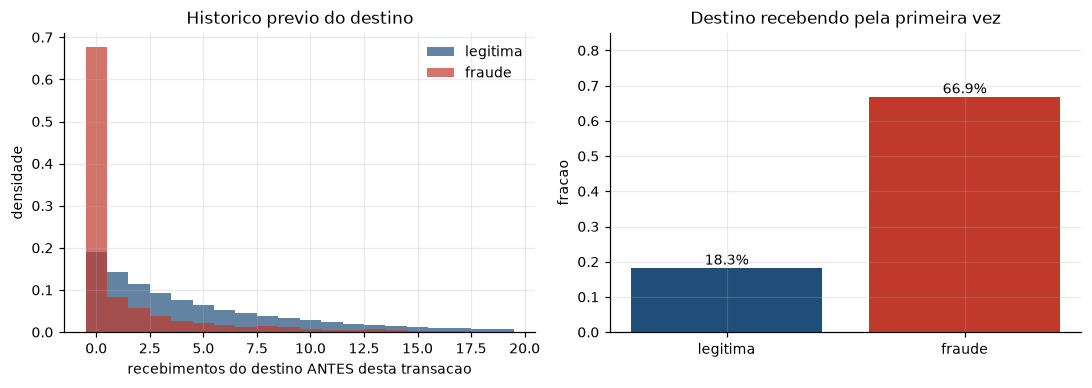

recebimentos previos — fraude: mediana 0, media 1.73
                    legitima: mediana 3, media 5.25


In [9]:
X, y, aux = features.build(df)
antes = X["destino_recebimentos_antes"]
estreia = X["destino_primeira_vez"]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))

bins = np.arange(0, 21) - 0.5
axes[0].hist(antes[y == 0].clip(upper=20), bins=bins, density=True, alpha=0.7,
             color=AZUL, label="legitima")
axes[0].hist(antes[y == 1].clip(upper=20), bins=bins, density=True, alpha=0.7,
             color=VERMELHO, label="fraude")
axes[0].set_xlabel("recebimentos do destino ANTES desta transacao")
axes[0].set_ylabel("densidade"); axes[0].legend(frameon=False)
axes[0].set_title("Historico previo do destino")

taxas = [estreia[y == 0].mean(), estreia[y == 1].mean()]
axes[1].bar(["legitima", "fraude"], taxas, color=[AZUL, VERMELHO])
for i, v in enumerate(taxas):
    axes[1].text(i, v, f"{v:.1%}", ha="center", va="bottom")
axes[1].set_ylabel("fracao"); axes[1].set_ylim(0, 0.85)
axes[1].set_title("Destino recebendo pela primeira vez")

plt.tight_layout(); plt.show()

print(f"recebimentos previos — fraude: mediana {antes[y==1].median():.0f}, "
      f"media {antes[y==1].mean():.2f}")
print(f"                    legitima: mediana {antes[y==0].median():.0f}, "
      f"media {antes[y==0].mean():.2f}")

Agora o sinal aparece, e ele é o **oposto** da hipótese inicial:
**66,9% das fraudes vão para uma conta que está recebendo pela primeira
vez**, contra 18,3% das transações legítimas. A mediana de recebimentos
prévios é 0 em fraude e 3 em transação legítima.

A conta laranja do PaySim não é a que acumula vítimas — é a conta nova,
estreando na base. E isso bate com o golpe de Pix real: a conta de
passagem é aberta para a ocasião, recebe e é esvaziada antes de o
bloqueio chegar.

Dois aprendizados desta seção, e o segundo vale mais que o primeiro:

1. O sinal do destino existe, e `destino_recebimentos_antes` acabou sendo
   a feature mais importante do modelo honesto.
2. **A agregação sobre o período inteiro escondeu o sinal por completo.**
   O mesmo `groupby` que parecia inofensivo mistura passado e futuro — e
   aqui ele não inflou o resultado, ele apagou. Calcular ponto a ponto no
   tempo não é preciosismo contra vazamento; às vezes é a única forma de
   enxergar o que está lá.

## 4. Contar fraudes não é barrar prejuízo

Último ponto, e o que define a métrica do projeto.

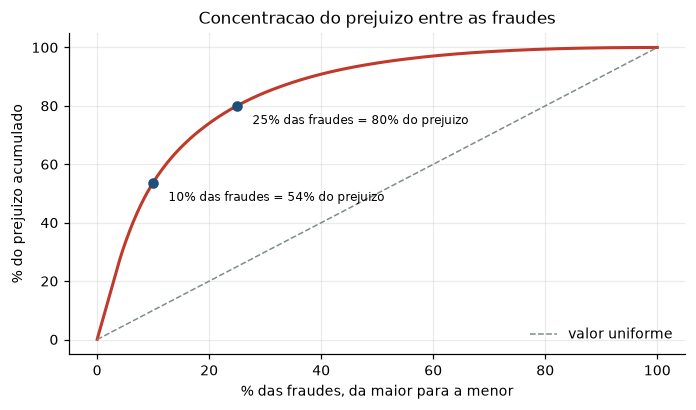

valor da fraude — mediana 441.423 | media 1.467.967 | maxima 10.000.000


In [10]:
vf = escopo.loc[escopo[config.TARGET] == 1, "valor"]
ordenado = np.sort(vf)[::-1]
acum = np.cumsum(ordenado) / ordenado.sum()
pct = np.arange(1, len(acum) + 1) / len(acum)

fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.plot(pct * 100, acum * 100, color=VERMELHO, lw=2)
ax.plot([0, 100], [0, 100], ls="--", color=CINZA, lw=1, label="valor uniforme")
for marca in (0.10, 0.25):
    i = int(marca * len(acum)) - 1
    ax.scatter([marca * 100], [acum[i] * 100], color=AZUL, zorder=5, s=35)
    ax.annotate(f"{marca:.0%} das fraudes = {acum[i]:.0%} do prejuizo",
                (marca * 100, acum[i] * 100), textcoords="offset points",
                xytext=(10, -12), fontsize=8)
ax.set_xlabel("% das fraudes, da maior para a menor")
ax.set_ylabel("% do prejuizo acumulado")
ax.set_title("Concentracao do prejuizo entre as fraudes")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

print(f"valor da fraude — mediana {vf.median():,.0f} | media {vf.mean():,.0f} | "
      f"maxima {vf.max():,.0f}".replace(",", "."))

O prejuízo é concentrado: uma minoria das fraudes responde pela maior
parte do dinheiro perdido.

Com capacidade de revisão finita, isso tem consequência direta. Uma mesa
que ordena a fila por probabilidade maximiza **quantas** fraudes pega.
Uma que ordena por `p × valor` maximiza **quanto** salva. Como o valor é
desigual, as duas ordens produzem filas diferentes — e a métrica que
distingue as duas é o VDR (fração do valor barrado), não o recall de
contagem.

É o que `src/triage.py` implementa e o que o app deixa mexer.